<a href="https://colab.research.google.com/github/ayooluwaestheraladetuyi-cpu/aiyetoro-shoreline-analysis/blob/main/Aiyetoro_XGBoost_SHAP_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
print("Aiyetoro Shoreline Change Analysis")
print("Study period: 2015–2025")
print("Study area: Aiyetoro, Ilaje, Ondo State, Nigeria")

Aiyetoro Shoreline Change Analysis
Study period: 2015–2025
Study area: Aiyetoro, Ilaje, Ondo State, Nigeria


In [3]:
!pip install xgboost shap pandas numpy matplotlib scikit-learn geopandas

In [4]:
import pandas as pd
import numpy as np
import geopandas as gpd
import xgboost as xgb
import shap
import matplotlib.pyplot as plt

print("All libraries imported successfully!")
print("Ready to prepare the Aiyetoro shoreline data.")

All libraries imported successfully!
Ready to prepare the Aiyetoro shoreline data.


In [5]:
from google.colab import files

uploaded = files.upload()

Saving Shoreline_2015_Metres.gpkg..gpkg to Shoreline_2015_Metres.gpkg..gpkg
Saving Shoreline_2016_Metres.gpkg to Shoreline_2016_Metres.gpkg
Saving Shoreline_2017_Metres.gpkg to Shoreline_2017_Metres.gpkg
Saving Shoreline_2018_Metres.gpkg to Shoreline_2018_Metres.gpkg
Saving Shoreline_2025_Metres.gpkg..gpkg to Shoreline_2025_Metres.gpkg..gpkg


In [6]:
import geopandas as gpd
import os

# List the uploaded files
print("Checking uploaded shoreline files...\n")

for filename in uploaded.keys():
    print(filename)

Checking uploaded shoreline files...

Shoreline_2015_Metres.gpkg..gpkg
Shoreline_2016_Metres.gpkg
Shoreline_2017_Metres.gpkg
Shoreline_2018_Metres.gpkg
Shoreline_2025_Metres.gpkg..gpkg


In [8]:
import geopandas as gpd

years = [2015, 2016, 2017, 2018, 2025]

for year in years:
    filename = f"Shoreline_{year}_Metres.gpkg.gpkg"

    if os.path.exists(filename):
        gdf = gpd.read_file(filename)

        print(f"\nYEAR: {year}")
        print("Features:", len(gdf))
        print("CRS:", gdf.crs)
        print("Geometry types:", gdf.geometry.geom_type.value_counts().to_dict())
        print("Bounds:", gdf.total_bounds)
    else:
        print(f"\nFile not found: {filename}")


File not found: Shoreline_2015_Metres.gpkg.gpkg

File not found: Shoreline_2016_Metres.gpkg.gpkg

File not found: Shoreline_2017_Metres.gpkg.gpkg

File not found: Shoreline_2018_Metres.gpkg.gpkg

File not found: Shoreline_2025_Metres.gpkg.gpkg


In [10]:
import os

print("Files currently available in Colab:\n")

for filename in os.listdir("/content"):
    print(filename)

Files currently available in Colab:

.config
Shoreline_2015_Metres.gpkg..gpkg
Shoreline_2018_Metres.gpkg
Shoreline_2017_Metres.gpkg
Shoreline_2016_Metres.gpkg
Shoreline_2025_Metres.gpkg..gpkg
sample_data


In [12]:
import os

files = [
    f for f in os.listdir("/content")
    if f.lower().endswith((".gpkg", ".gpkg.gpkg"))
]

print("SHORELINE FILES FOUND:", len(files))

for f in files:
    print(repr(f))

SHORELINE FILES FOUND: 5
'Shoreline_2015_Metres.gpkg..gpkg'
'Shoreline_2018_Metres.gpkg'
'Shoreline_2017_Metres.gpkg'
'Shoreline_2016_Metres.gpkg'
'Shoreline_2025_Metres.gpkg..gpkg'


In [14]:
import os
import geopandas as gpd

# Find the uploaded GeoPackage files
files = [
    os.path.join("/content", f)
    for f in os.listdir("/content")
    if f.lower().endswith(".gpkg")
]

print("Number of GeoPackage files found:", len(files))

# Inspect each file
for path in files:
    try:
        gdf = gpd.read_file(path)

        print("\nFile:", os.path.basename(path))
        print("Number of features:", len(gdf))
        print("Coordinate reference system:", gdf.crs)
        print("Geometry types:", gdf.geometry.geom_type.value_counts().to_dict())
        print("Columns:", list(gdf.columns))

    except Exception as e:
        print("\nCould not read:", os.path.basename(path))
        print("Error:", e)

Number of GeoPackage files found: 5

File: Shoreline_2015_Metres.gpkg..gpkg
Number of features: 7
Coordinate reference system: EPSG:32631
Geometry types: {'MultiLineString': 7}
Columns: ['ndwi_thres', 'year', 'shoreline', 'count', 'geometry']

File: Shoreline_2018_Metres.gpkg
Number of features: 17
Coordinate reference system: EPSG:32631
Geometry types: {'MultiLineString': 17}
Columns: ['ndwi_thres', 'year', 'shoreline', 'count', 'geometry']

File: Shoreline_2017_Metres.gpkg
Number of features: 25
Coordinate reference system: EPSG:32631
Geometry types: {'MultiLineString': 25}
Columns: ['ndwi_thres', 'year', 'shoreline', 'count', 'geometry']

File: Shoreline_2016_Metres.gpkg
Number of features: 1
Coordinate reference system: EPSG:32631
Geometry types: {'MultiLineString': 1}
Columns: ['ndwi_thres', 'year', 'shoreline', 'count', 'geometry']

File: Shoreline_2025_Metres.gpkg..gpkg
Number of features: 10
Coordinate reference system: EPSG:32631
Geometry types: {'MultiLineString': 10}
Columns

In [15]:
print("Files found:", len(files))

for path in files:
    gdf = gpd.read_file(path)
    print(os.path.basename(path), "| CRS:", gdf.crs,
          "| Geometry:", list(gdf.geometry.geom_type.unique()))

Files found: 5
Shoreline_2015_Metres.gpkg..gpkg | CRS: EPSG:32631 | Geometry: ['MultiLineString']
Shoreline_2018_Metres.gpkg | CRS: EPSG:32631 | Geometry: ['MultiLineString']
Shoreline_2017_Metres.gpkg | CRS: EPSG:32631 | Geometry: ['MultiLineString']
Shoreline_2016_Metres.gpkg | CRS: EPSG:32631 | Geometry: ['MultiLineString']
Shoreline_2025_Metres.gpkg..gpkg | CRS: EPSG:32631 | Geometry: ['MultiLineString']


In [16]:
import os
import geopandas as gpd
import pandas as pd

results = []

for path in files:
    gdf = gpd.read_file(path)

    # Calculate total length in metres
    total_length_m = gdf.geometry.length.sum()

    # Identify the year from the filename
    filename = os.path.basename(path)
    year = next(
        (y for y in [2015, 2016, 2017, 2018, 2025]
         if str(y) in filename),
        None
    )

    results.append({
        "Year": year,
        "Number_of_features": len(gdf),
        "Total_mapped_length_m": round(total_length_m, 2),
        "Total_mapped_length_km": round(total_length_m / 1000, 3)
    })

shoreline_summary = pd.DataFrame(results).sort_values("Year")

display(shoreline_summary)

,Year,Number_of_features,Total_mapped_length_m,Total_mapped_length_km
0,2015,7,24034.49,24.034
3,2016,1,13478.40,13.478
2,2017,25,42462.74,42.463
1,2018,17,30117.64,30.118
4,2025,10,15744.89,15.745


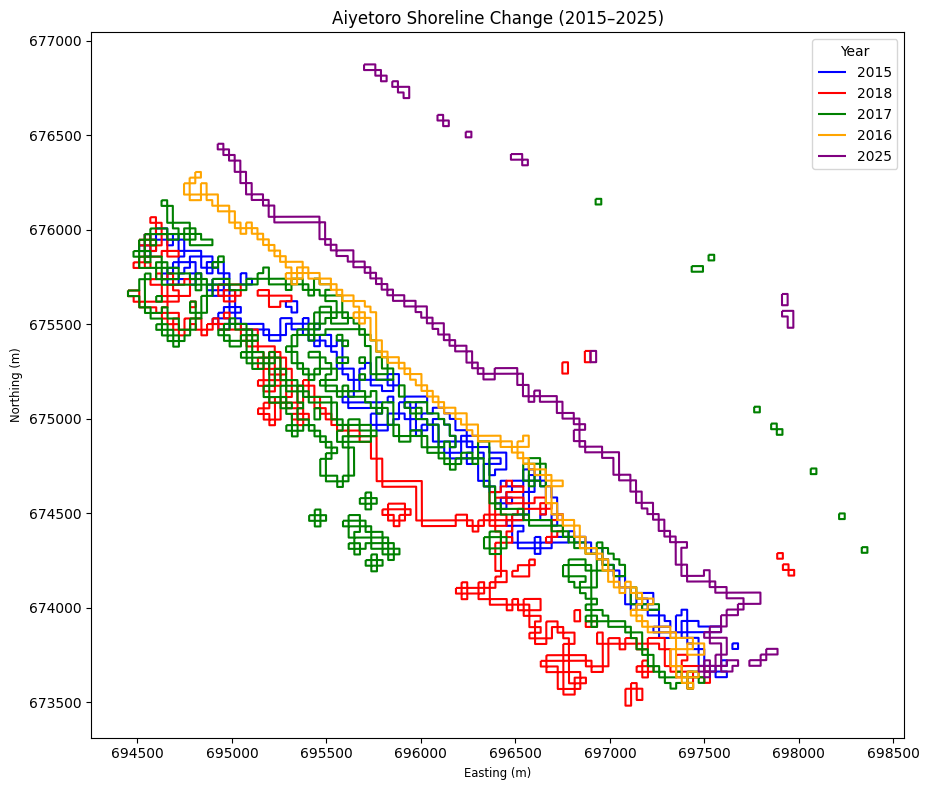

In [23]:
import matplotlib.pyplot as plt
import geopandas as gpd
import os

# Match the colours used in QGIS
shoreline_colors = {
    2015: "#0000FF",  # Blue
    2016: "#FFA500",  # Orange
    2017: "#008000",  # Green
    2018: "#FF0000",  # Red
    2025: "#800080"   # Purple
}

fig, ax = plt.subplots(figsize=(12, 8))

for path in files:
    gdf = gpd.read_file(path)

    filename = os.path.basename(path)

    year = next(
        (y for y in shoreline_colors if str(y) in filename),
        None
    )

    if year is not None:
        gdf.plot(
            ax=ax,
            color=shoreline_colors[year],
            linewidth=1.5,
            label=str(year)
        )

ax.set_title("Aiyetoro Shoreline Change (2015–2025)")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.legend(title="Year")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

In [25]:
import geopandas as gpd
import pandas as pd
import os

summary = []

for path in files:
    gdf = gpd.read_file(path)

    year = next(
        (y for y in [2015, 2016, 2017, 2018, 2025]
         if str(y) in os.path.basename(path)),
        None
    )

    summary.append({
        "Year": year,
        "Features": len(gdf),
        "Empty geometries": gdf.geometry.is_empty.sum(),
        "Invalid geometries": (~gdf.geometry.is_valid).sum(),
        "CRS": str(gdf.crs),
        "Total length (m)": round(gdf.geometry.length.sum(), 2)
    })

display(pd.DataFrame(summary).sort_values("Year"))

,Year,Features,Empty geometries,Invalid geometries,CRS,Total length (m)
0,2015,7,0,0,EPSG:32631,24034.49
3,2016,1,0,0,EPSG:32631,13478.40
2,2017,25,0,0,EPSG:32631,42462.74
1,2018,17,0,0,EPSG:32631,30117.64
4,2025,10,0,0,EPSG:32631,15744.89


In [26]:
import geopandas as gpd
import pandas as pd
import os

segment_results = []

for path in files:
    gdf = gpd.read_file(path)

    year = next(
        (y for y in [2015, 2016, 2017, 2018, 2025]
         if str(y) in os.path.basename(path)),
        None
    )

    for i, geom in enumerate(gdf.geometry):
        segment_results.append({
            "Year": year,
            "Feature_ID": i + 1,
            "Length_m": round(geom.length, 2)
        })

segments = pd.DataFrame(segment_results)

display(
    segments.sort_values(["Year", "Length_m"])
    .reset_index(drop=True)
)

,Year,Feature_ID,Length_m
0,2015,4,119.28
1,2015,5,119.28
2,2015,6,119.28
3,2015,7,119.28
4,2015,2,238.55
5,2015,3,238.55
6,2015,1,23080.28
7,2016,1,13478.40
8,2017,1,119.27
9,2017,10,119.28


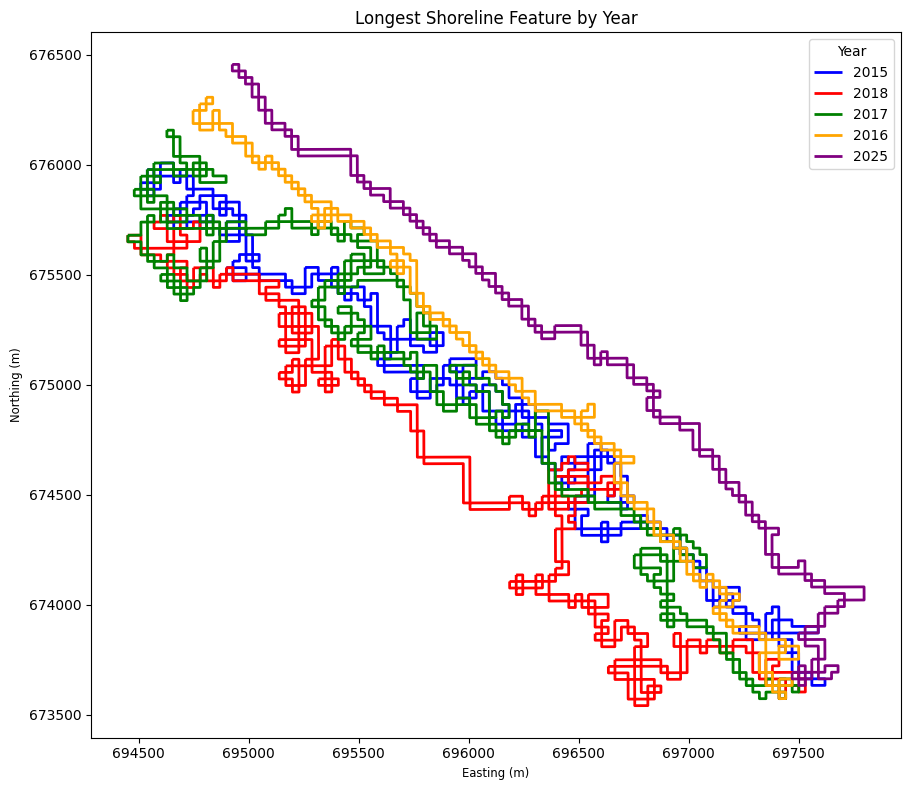

In [28]:
import geopandas as gpd
import matplotlib.pyplot as plt
import os

shoreline_colors = {
    2015: "#0000FF",  # Blue
    2016: "#FFA500",  # Orange
    2017: "#008000",  # Green
    2018: "#FF0000",  # Red
    2025: "#800080"   # Purple
}

fig, ax = plt.subplots(figsize=(12, 8))

for path in files:
    gdf = gpd.read_file(path)

    year = next(
        (y for y in shoreline_colors
         if str(y) in os.path.basename(path)),
        None
    )

    if year is None or gdf.empty:
        continue

    # Select the longest feature for visual inspection
    longest = gdf.loc[[gdf.geometry.length.idxmax()]]

    longest.plot(
        ax=ax,
        color=shoreline_colors[year],
        linewidth=2,
        label=str(year)
    )

ax.set_title("Longest Shoreline Feature by Year")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.legend(title="Year")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

In [29]:
import geopandas as gpd
import pandas as pd
import os

extent_results = []

for path in files:
    gdf = gpd.read_file(path)

    minx, miny, maxx, maxy = gdf.total_bounds

    year = next(
        (y for y in [2015, 2016, 2017, 2018, 2025]
         if str(y) in os.path.basename(path)),
        None
    )

    extent_results.append({
        "Year": year,
        "Min_Easting": round(minx, 2),
        "Min_Northing": round(miny, 2),
        "Max_Easting": round(maxx, 2),
        "Max_Northing": round(maxy, 2)
    })

extent_df = pd.DataFrame(extent_results).sort_values("Year")

display(extent_df)

,Year,Min_Easting,Min_Northing,Max_Easting,Max_Northing
0,2015,694508.85,673633.27,697678.23,676008.12
3,2016,694746.44,673573.16,697499.33,676306.75
2,2017,694449.97,673572.87,698362.73,676164.70
1,2018,694449.97,673482.67,697975.29,676067.54
4,2025,694924.75,673633.07,697970.93,676876.08


In [30]:
import geopandas as gpd
import os

for path in files:
    gdf = gpd.read_file(path)

    year = next(
        (y for y in [2015, 2016, 2017, 2018, 2025]
         if str(y) in os.path.basename(path)),
        None
    )

    print(f"\n{'=' * 40}")
    print(f"YEAR: {year}")
    print("ATTRIBUTE COLUMNS:")
    print(gdf.drop(columns="geometry").columns.tolist())

    print("\nFIRST THREE RECORDS:")
    display(gdf.drop(columns="geometry").head(3))


YEAR: 2015
ATTRIBUTE COLUMNS:
['ndwi_thres', 'year', 'shoreline', 'count']

FIRST THREE RECORDS:


,ndwi_thres,year,shoreline,count
0,0,2015,1,287
1,0,2015,1,3
2,0,2015,1,3



YEAR: 2018
ATTRIBUTE COLUMNS:
['ndwi_thres', 'year', 'shoreline', 'count']

FIRST THREE RECORDS:


,ndwi_thres,year,shoreline,count
0,0,2018,1,19
1,0,2018,1,279
2,0,2018,1,1



YEAR: 2017
ATTRIBUTE COLUMNS:
['ndwi_thres', 'year', 'shoreline', 'count']

FIRST THREE RECORDS:


,ndwi_thres,year,shoreline,count
0,0,2017,1,1
1,0,2017,1,316
2,0,2017,1,2



YEAR: 2016
ATTRIBUTE COLUMNS:
['ndwi_thres', 'year', 'shoreline', 'count']

FIRST THREE RECORDS:


,ndwi_thres,year,shoreline,count
0,0,2016,1,147



YEAR: 2025
ATTRIBUTE COLUMNS:
['ndwi_thres', 'year', 'shoreline', 'count']

FIRST THREE RECORDS:


,ndwi_thres,year,shoreline,count
0,0,2025,1,151
1,0,2025,1,4
2,0,2025,1,4
